# Mobile Price Clasification
---

## 1. Business Understanding
### 1.1 Latar Belakang, masalah, Solusi
1. **Latar Belakang**: Seseorang baru saja mendirikan perusahaan smartphone dan berambisi bersaing dengan raksasa industri global.
2. **Masalah**:Bagaimana cara menentukan harga jual yang kompetitif tanpa berakhir pada kebangkrutan? Di pasar yang ketat, asumsi semata adalah jalan menuju kegagalan. Orang tersebut membutuhkan strategi berbasis data.
3. **Solusi**: Membuat Model *Machine Learning* untuk memprediksi kelas harga (Price Range) sebuah ponsel cerdas berdasarkan spesifikasi perangkat kerasnya menggunakan Machine Learning Decision Tree

### 1.2 Deskripsi Dataset `data_set.csv`
    1.`battery_power`:Kapasitas energi baterai maksimal sebelum habis sepenuhnya (dalam mAh)
    2.`blue`:Ketersediaan fitur Bluetooth pada ponsel
    3.`clock_speed`:Kecepatan mikroprosesor dalam mengeksekusi instruksi
    4.`dual_sim`:Dukungan penggunaan dua kartu SIM sekaligus (Dual SIM)
    5.`fc`:Resolusi kamera depan dalam ukuran megapiksel
    6.`four_g`:Dukungan konektivitas jaringan 4G
    7.`int_memory`:Kapasitas penyimpanan memori internal (dalam Gigabytes/GB)
    8.`m_dep`:Ketebalan fisik ponsel (dalam cm)
    9.`mobile_wt`:Berat fisik ponsel
    10.`n_cores`:Jumlah core prosesor
    11.`pc`:Resolusi kamera utama/belakang dalam ukuran megapiksel
    12.`px_height`:Resolusi gambar layar dari segi tingginya (dalam piksel)
    13.`px_width`:Resolusi gambar layar dari segi lebarnya (dalam piksel)
    14.`ram`:Kapasitas Random Access Memory (RAM) (dalam Megabytes/MB)
    15.`sc_h`:Tinggi layar fisik ponsel (dalam cm)
    16.`sc_w`:Lebar layar fisik ponsel (dalam cm)
    17.`talk_time`:Waktu bicara terlama yang bisa dicapai dalam satu kali pengisian daya penuh
    18.`three_g`:Dukungan konektivitas jaringan 3G
    19.`touch_screen`:Ketersediaan fitur layar sentuh (touchscreen)
    20.`wifi`:Ketersediaan fitur konektivitas jaringan Wi-Fi
    21.`price_range`:Rentang harga target: 0 (murah), 1 (menengah), 2 (mahal), dan 3 (sangat mahal)

---
## 2. Data Preparation

### 2.1 Import Library

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 2.2 Load Dataset

In [2]:
df = pd.read_csv('data_set.csv')
df.columns = df.columns.str.strip()

### 2.3 Load Data Teratas Dan Data Terbawah

In [3]:
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842.0,0.0,2.2,0.0,1.0,0.0,7.0,0.6,188.0,2.0,...,20.0,756.0,2549.0,9.0,7.0,19.0,0.0,0.0,1.0,1.0
1,1021.0,1.0,0.5,1.0,0.0,1.0,53.0,0.7,136.0,3.0,...,905.0,1988.0,2631.0,17.0,3.0,7.0,1.0,1.0,0.0,2.0
2,563.0,1.0,0.5,1.0,2.0,1.0,41.0,0.9,145.0,5.0,...,1263.0,NaN,2603.0,11.0,2.0,9.0,1.0,1.0,0.0,2.0
3,615.0,1.0,2.5,0.0,0.0,0.0,10.0,0.8,131.0,6.0,...,1216.0,1786.0,2769.0,16.0,8.0,11.0,1.0,0.0,0.0,2.0
4,1821.0,1.0,1.2,0.0,NaN,1.0,44.0,0.6,141.0,2.0,...,1208.0,1212.0,NaN,8.0,2.0,15.0,1.0,1.0,0.0,1.0


In [4]:
df.tail()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
1995,794.0,1.0,0.5,1.0,0.0,1.0,2.0,0.8,106.0,6.0,...,1222.0,1890.0,668.0,13.0,4.0,19.0,1.0,1.0,0.0,0.0
1996,1965.0,1.0,2.6,1.0,0.0,0.0,39.0,0.2,187.0,4.0,...,915.0,1965.0,2032.0,11.0,10.0,16.0,1.0,1.0,1.0,2.0
1997,1911.0,0.0,0.9,1.0,1.0,1.0,36.0,0.7,108.0,8.0,...,NaN,1632.0,3057.0,9.0,1.0,5.0,1.0,1.0,0.0,3.0
1998,1512.0,0.0,0.9,0.0,4.0,1.0,46.0,0.1,145.0,5.0,...,336.0,670.0,869.0,18.0,10.0,19.0,1.0,1.0,1.0,0.0
1999,510.0,1.0,2.0,1.0,5.0,1.0,45.0,0.9,168.0,6.0,...,483.0,754.0,3919.0,19.0,4.0,NaN,1.0,1.0,1.0,3.0


### 2.4 Tampilkan Informasi Data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  1960 non-null   float64
 1   blue           1960 non-null   float64
 2   clock_speed    1960 non-null   float64
 3   dual_sim       1960 non-null   float64
 4   fc             1960 non-null   float64
 5   four_g         1960 non-null   float64
 6   int_memory     1960 non-null   float64
 7   m_dep          1960 non-null   float64
 8   mobile_wt      1960 non-null   float64
 9   n_cores        1960 non-null   float64
 10  pc             1960 non-null   float64
 11  px_height      1960 non-null   float64
 12  px_width       1960 non-null   float64
 13  ram            1960 non-null   float64
 14  sc_h           1960 non-null   float64
 15  sc_w           1960 non-null   float64
 16  talk_time      1960 non-null   float64
 17  three_g        1960 non-null   float64
 18  touch_screen   1960

### 2.5 Memeriksa Jumlah Data, Missing Value, dan Data Duplikat

In [6]:
print(f'Jumlah Data: {df.size}')

print(f'\n Total Missing Value: {df.isnull().sum().sum()}')
print(f'---- Missing Value Setiap Kolom ---- \n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'Jumlah Data Duplikat: {df.duplicated().sum()}')

Jumlah Data: 42000

 Total Missing Value: 820
---- Missing Value Setiap Kolom ---- 
battery_power    40
blue             40
clock_speed      40
dual_sim         40
fc               40
four_g           40
int_memory       40
m_dep            40
mobile_wt        40
n_cores          40
pc               40
px_height        40
px_width         40
ram              40
sc_h             40
sc_w             40
talk_time        40
three_g          40
touch_screen     40
wifi             40
price_range      20
dtype: int64
Jumlah Data Duplikat: 0


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Tampilkan Deskripsi Data

In [7]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,...,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1960.000000,1980.000000
mean,1240.528061,0.495408,1.521633,0.511224,4.313776,0.519898,32.090816,0.501582,140.076531,4.525510,...,644.650510,1251.482653,2125.535714,12.330612,5.770918,11.020918,0.764796,0.502551,0.504592,1.495455
std,439.490060,0.500107,0.815008,0.500002,4.353569,0.499731,18.111698,0.288688,35.401342,2.287718,...,445.471698,433.463632,1084.420824,4.216921,4.365987,5.451262,0.424235,0.500121,0.500107,1.116951
min,501.000000,0.000000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,852.750000,0.000000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,280.750000,874.000000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.000000
50%,1230.500000,0.000000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,140.000000,4.000000,...,562.500000,1247.000000,2150.000000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.000000
75%,1617.000000,1.000000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,946.250000,1634.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.000000
max,1998.000000,1.000000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


### 3.2 Analisis Outlier Dengan IQR dan Z-Score

In [8]:
outliers = []
out = []
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        mean = df[col].mean()
        median = df[col].median()
        std = df[col].std()
        lower = q1 - 1.5 * iqr
        upper = q1 + 1.5 * iqr
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z_score = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standar deviasi': std,
            'min': df[col].min(),
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': df[col].max(),
            'batas bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z_Score)': outlier_z_score.shape[0],
        })
pd.DataFrame(outliers)

,nama kolom,mean,standar deviasi,min,q1,median,q3,max,batas bawah,batas atas,outlier (IQR),outlier (Z_Score)
0,battery_power,1240.528061,439.490060,501.0,852.75,1230.5,1617.00,1998.0,-293.625,1999.125,0,0
1,blue,0.495408,0.500107,0.0,0.00,0.0,1.00,1.0,-1.500,1.500,0,0
2,clock_speed,1.521633,0.815008,0.5,0.70,1.5,2.20,3.0,-1.550,2.950,26,0
3,dual_sim,0.511224,0.500002,0.0,0.00,1.0,1.00,1.0,-1.500,1.500,0,0
4,fc,4.313776,4.353569,0.0,1.00,3.0,7.00,19.0,-8.000,10.000,218,12
5,four_g,0.519898,0.499731,0.0,0.00,1.0,1.00,1.0,-1.500,1.500,0,0
6,int_memory,32.090816,18.111698,2.0,16.00,32.0,48.00,64.0,-32.000,64.000,0,0
7,m_dep,0.501582,0.288688,0.1,0.20,0.5,0.80,1.0,-0.700,1.100,0,0
8,mobile_wt,140.076531,35.401342,80.0,109.00,140.0,170.00,200.0,17.500,200.500,0,0
9,n_cores,4.525510,2.287718,1.0,3.00,4.0,7.00,8.0,-3.000,9.000,0,0


### 3.3 Visualisasi Outlier dengan Boxplot

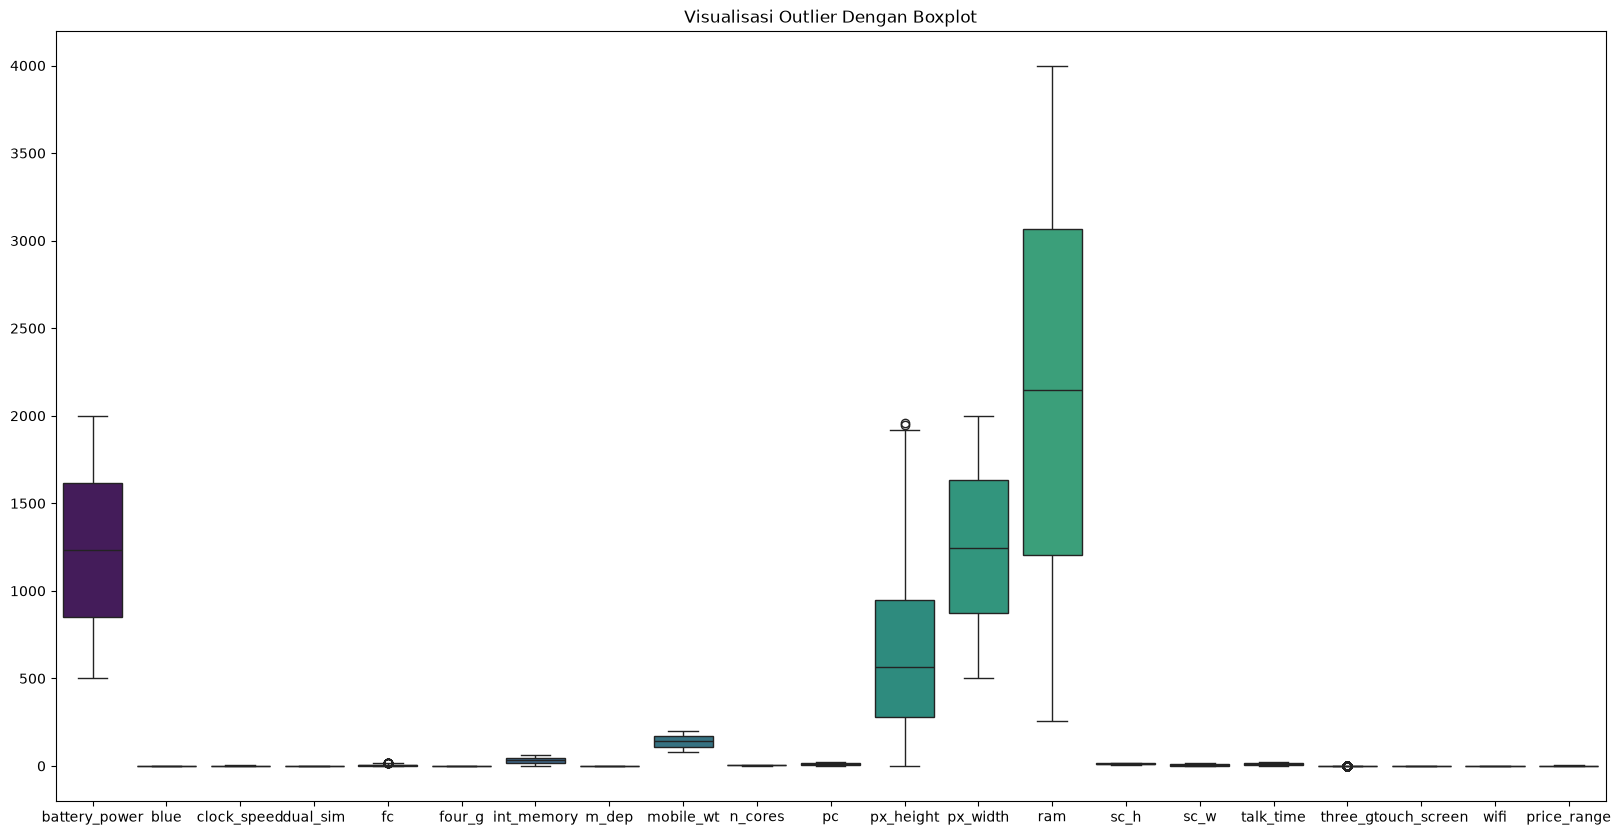

In [9]:
plt.figure(figsize=(20,10))
sns.boxplot(data=df, palette='viridis')
plt.title('Visualisasi Outlier Dengan Boxplot')
plt.show()

Beberapa kolom memiliki nilai yang besar seperti kolom `battery_power`, `px_height`, `px_width`, dan `ram`. maka untuk langkah selanjutnya, perlu dilakukan standarisasi pada kolom kolom fitur.

### 3.4 Analisis Distribusi Data

/tmp/ipykernel_29827/1700280976.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='n_cores', palette='viridis', ax=axes[1,0])


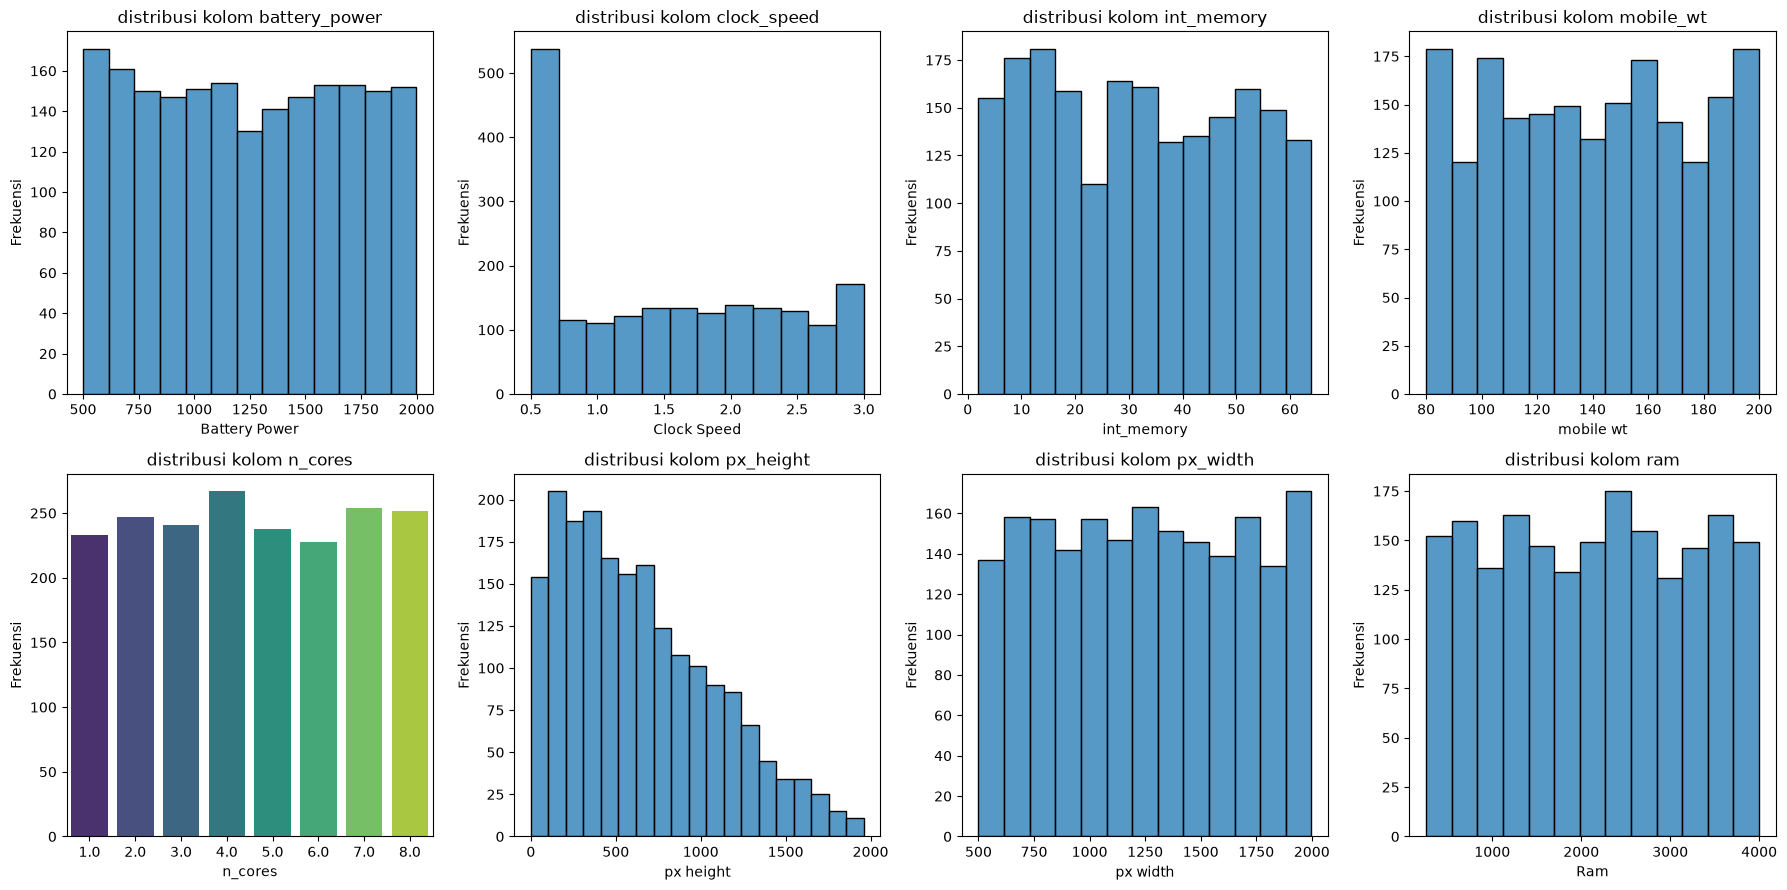

In [10]:
figure, axes = plt.subplots(2, 4, figsize=(18,9))

sns.histplot(data=df, x='battery_power', ax=axes[0,0])
axes[0,0].set_title('distribusi kolom battery_power')
axes[0,0].set_xlabel('Battery Power')
axes[0,0].set_ylabel('Frekuensi')

sns.histplot(data=df, x='clock_speed', ax=axes[0,1])
axes[0,1].set_title('distribusi kolom clock_speed')
axes[0,1].set_xlabel('Clock Speed')
axes[0,1].set_ylabel('Frekuensi')

sns.histplot(data=df, x='int_memory', ax=axes[0,2])
axes[0,2].set_title('distribusi kolom int_memory')
axes[0,2].set_xlabel('int_memory')
axes[0,2].set_ylabel('Frekuensi')

sns.histplot(data=df, x='mobile_wt', ax=axes[0,3])
axes[0,3].set_title('distribusi kolom mobile_wt')
axes[0,3].set_xlabel('mobile wt')
axes[0,3].set_ylabel('Frekuensi')

sns.countplot(data=df, x='n_cores', palette='viridis', ax=axes[1,0])
axes[1,0].set_title('distribusi kolom n_cores')
axes[1,0].set_xlabel('n_cores')
axes[1,0].set_ylabel('Frekuensi')

sns.histplot(data=df, x='px_height', ax=axes[1,1])
axes[1,1].set_title('distribusi kolom px_height')
axes[1,1].set_xlabel('px height')
axes[1,1].set_ylabel('Frekuensi')

sns.histplot(data=df, x='px_width', ax=axes[1,2])
axes[1,2].set_title('distribusi kolom px_width')
axes[1,2].set_xlabel('px width')
axes[1,2].set_ylabel('Frekuensi')

sns.histplot(data=df, x='ram', ax=axes[1,3])
axes[1,3].set_title('distribusi kolom ram')
axes[1,3].set_xlabel('Ram')
axes[1,3].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

### 3.5 Distribusi Pada Kolom Target

<function matplotlib.pyplot.show(close=None, block=None)>

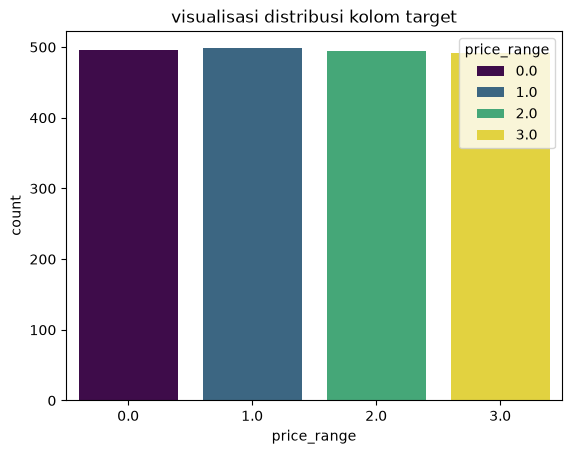

In [11]:
sns.countplot(data=df, x='price_range', palette='viridis', hue='price_range')
plt.title('visualisasi distribusi kolom target')
plt.show

### 3.6 Visualisasi Korelasi Antar kolom

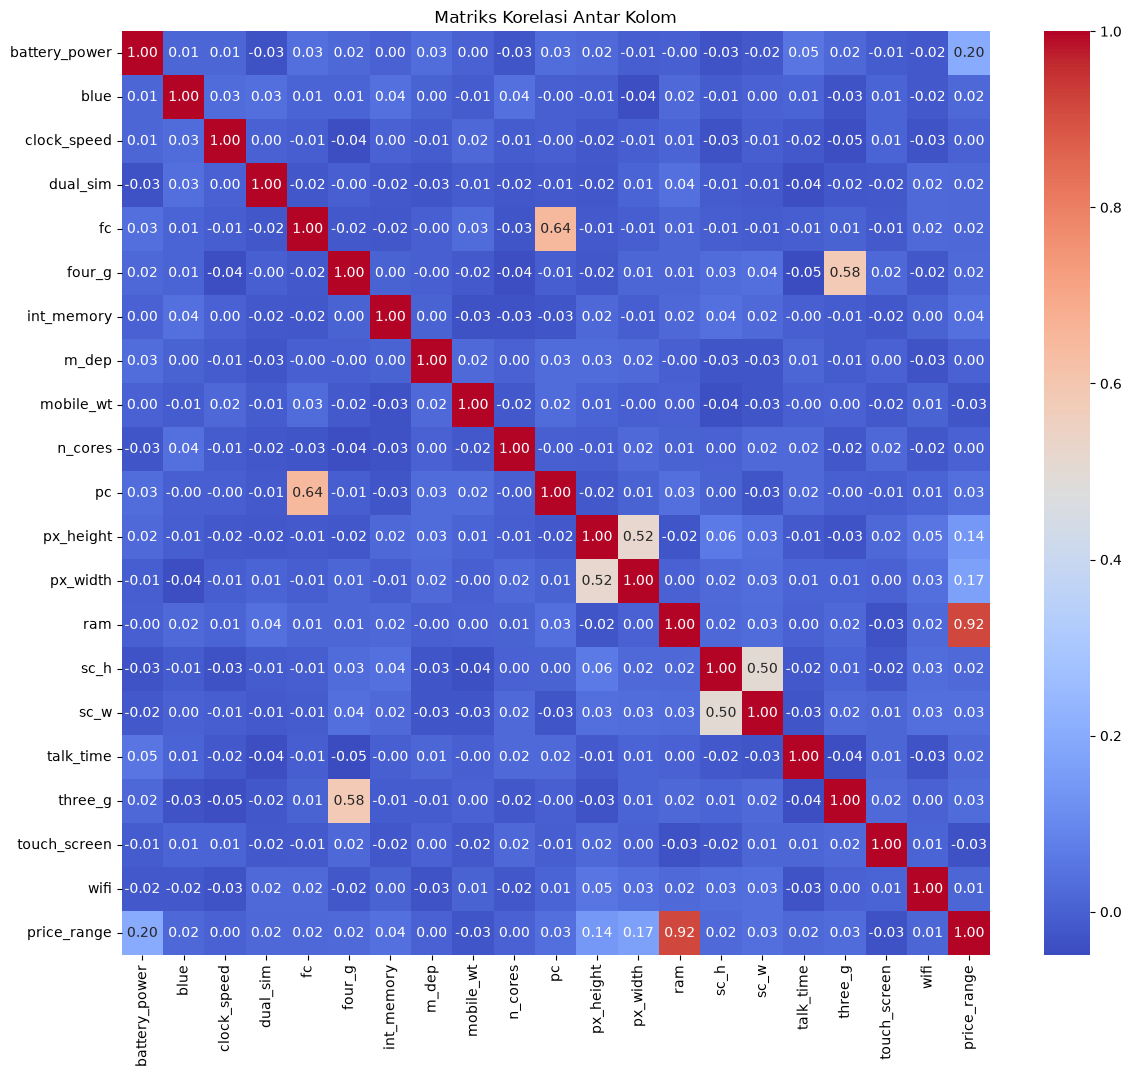

In [12]:
plt.figure(figsize=(14, 12))
korelasi = df.corr(method='pearson')
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriks Korelasi Antar Kolom')
plt.show()

---

## 4. Data Preprocessing

## 4.1 Memeriksa Missing Value dan Duplikasi Data

In [13]:
print("--- Jumlah Missing Value ---")
print(df.isnull().sum())
print("\n--- Jumlah Duplikasi Data ---")
print(df.duplicated().sum())

--- Jumlah Missing Value ---
battery_power    40
blue             40
clock_speed      40
dual_sim         40
fc               40
four_g           40
int_memory       40
m_dep            40
mobile_wt        40
n_cores          40
pc               40
px_height        40
px_width         40
ram              40
sc_h             40
sc_w             40
talk_time        40
three_g          40
touch_screen     40
wifi             40
price_range      20
dtype: int64

--- Jumlah Duplikasi Data ---
0


In [14]:
df['battery_power'] = df['battery_power'].fillna(df['battery_power'].median())
df['blue'] = df['blue'].fillna(df['blue'].mode().iloc[0])
df['clock_speed'] = df['clock_speed'].fillna(df['clock_speed'].median())
df['dual_sim'] = df['dual_sim'].fillna(df['dual_sim'].mode().iloc[0])
df['fc'] = df['fc'].fillna(df['fc'].median())
df['four_g'] = df['four_g'].fillna(df['four_g'].mode().iloc[0])
df['int_memory'] = df['int_memory'].fillna(df['int_memory'].median())
df['m_dep'] = df['m_dep'].fillna(df['m_dep'].median())
df['mobile_wt'] = df['mobile_wt'].fillna(df['mobile_wt'].median())
df['n_cores'] = df['n_cores'].fillna(df['n_cores'].median())
df['pc'] = df['pc'].fillna(df['pc'].median())
df['px_height'] = df['px_height'].fillna(df['px_height'].median())
df['px_width'] = df['px_width'].fillna(df['px_width'].median())
df['ram'] = df['ram'].fillna(df['ram'].median())
df['sc_h'] = df['sc_h'].fillna(df['sc_h'].median())
df['sc_w'] = df['sc_w'].fillna(df['sc_w'].median())
df['talk_time'] = df['talk_time'].fillna(df['talk_time'].median())
df['three_g'] = df['three_g'].fillna(df['three_g'].mode().iloc[0])
df['touch_screen'] = df['touch_screen'].fillna(df['touch_screen'].mode().iloc[0])
df['wifi'] = df['wifi'].fillna(df['wifi'].mode().iloc[0])
df = df.dropna(subset=['price_range'])
df.isnull().sum()

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

In [15]:
Q1 = df['fc'].quantile(0.25)
Q3 = df['fc'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df['fc'] = np.clip((df['fc'] > lower) | (df['fc'] < upper))
print(df[(df['fc'] < lower ) | (df['fc'] > upper)])

Empty DataFrame
Columns: [battery_power, blue, clock_speed, dual_sim, fc, four_g, int_memory, m_dep, mobile_wt, n_cores, pc, px_height, px_width, ram, sc_h, sc_w, talk_time, three_g, touch_screen, wifi, price_range]
Index: []

[0 rows x 21 columns]


In [16]:
Q1 = df['px_height'].quantile(0.25)
Q3 = df['px_height'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df['px_height'] = np.clip((df['px_height'] > lower) | (df['px_height'] < upper))
print(df[(df['px_height'] < lower ) | (df['px_height'] > upper)])

Empty DataFrame
Columns: [battery_power, blue, clock_speed, dual_sim, fc, four_g, int_memory, m_dep, mobile_wt, n_cores, pc, px_height, px_width, ram, sc_h, sc_w, talk_time, three_g, touch_screen, wifi, price_range]
Index: []

[0 rows x 21 columns]


In [17]:
Q1 = df['ram'].quantile(0.25)
Q3 = df['ram'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df['ram'] = np.clip((df['ram'] > lower) | (df['ram'] < upper))
print(df[(df['ram'] < lower ) | (df['ram'] > upper)])

Empty DataFrame
Columns: [battery_power, blue, clock_speed, dual_sim, fc, four_g, int_memory, m_dep, mobile_wt, n_cores, pc, px_height, px_width, ram, sc_h, sc_w, talk_time, three_g, touch_screen, wifi, price_range]
Index: []

[0 rows x 21 columns]


In [18]:
Q1 = df['clock_speed'].quantile(0.25)
Q3 = df['clock_speed'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df['clock_speed'] = np.clip((df['clock_speed'] > lower) | (df['clock_speed'] < upper))
print(df[(df['clock_speed'] < lower ) | (df['clock_speed'] > upper)])

Empty DataFrame
Columns: [battery_power, blue, clock_speed, dual_sim, fc, four_g, int_memory, m_dep, mobile_wt, n_cores, pc, px_height, px_width, ram, sc_h, sc_w, talk_time, three_g, touch_screen, wifi, price_range]
Index: []

[0 rows x 21 columns]


In [19]:
X = df.drop(columns=['price_range'])
y = df['price_range']

print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk y : {len(y)} label")

np.random.seed(43)
acak = np.random.permutation(len(X))
batas = int(0.8 * len(X))

X_train = X.iloc[acak[:batas]]
X_test = X.iloc[acak[batas:]]
y_train = X.iloc[acak[:batas]]
y_test = X.iloc[acak[batas:]]

print(f"Data Latih : {len(X_train)} baris (80%)")
print(f"Data Latih : {len(X_test)} baris (20%)")

Bentuk X : 1980 baris, 20 kolom
Bentuk y : 1980 label
Data Latih : 1584 baris (80%)
Data Latih : 396 baris (20%)


In [20]:
mean_X = X.mean()
std_X = X.std()

X_scaled_df = (X - mean_X) / std_X
scaled_data = X_scaled_df.values

X_scaled_df.describe()


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
count,1.980000e+03,1.980000e+03,0.0,1.980000e+03,0.0,1.980000e+03,1.980000e+03,1.980000e+03,1.980000e+03,1.980000e+03,1.980000e+03,0.0,1.980000e+03,0.0,1.980000e+03,1.980000e+03,1.980000e+03,1.980000e+03,1.980000e+03,1.980000e+03
mean,2.440248e-16,-6.818339e-17,NaN,-2.781165e-17,NaN,1.794300e-18,-1.686642e-16,-1.570012e-16,3.875688e-16,-5.203470e-17,1.256010e-16,NaN,1.282924e-16,NaN,-1.256010e-17,-6.885626e-17,5.562329e-17,7.894919e-17,-8.971499e-17,6.997769e-17
std,1.000000e+00,1.000000e+00,NaN,1.000000e+00,NaN,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,NaN,1.000000e+00,NaN,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-1.701866e+00,-9.698975e-01,NaN,-1.043100e+00,NaN,-1.060139e+00,-1.676465e+00,-1.405482e+00,-1.712627e+00,-1.548465e+00,-1.654583e+00,NaN,-1.749367e+00,NaN,-1.752010e+00,-1.330529e+00,-1.668722e+00,-1.822489e+00,-1.025321e+00,-1.028435e+00
25%,-8.690962e-01,-9.698975e-01,NaN,-1.043100e+00,NaN,-1.060139e+00,-8.957183e-01,-1.055217e+00,-8.857827e-01,-6.669352e-01,-8.222046e-01,NaN,-8.672807e-01,NaN,-7.951818e-01,-8.685886e-01,-9.284804e-01,5.484231e-01,-1.025321e+00,-1.028435e+00
50%,-2.251368e-02,-9.698975e-01,NaN,9.581966e-01,NaN,9.427958e-01,-3.436188e-03,-4.422535e-03,-1.915190e-03,-2.261703e-01,1.017351e-02,NaN,-9.648633e-03,NaN,-7.756103e-02,-1.756775e-01,-3.177807e-03,5.484231e-01,9.748122e-01,9.718605e-01
75%,8.419098e-01,1.030516e+00,NaN,9.581966e-01,NaN,9.427958e-01,8.330783e-01,6.961071e-01,8.320566e-01,1.096124e+00,8.425517e-01,NaN,8.677794e-01,NaN,8.792667e-01,7.482040e-01,9.221248e-01,5.484231e-01,9.748122e-01,9.718605e-01
max,1.744317e+00,1.030516e+00,NaN,9.581966e-01,NaN,9.427958e-01,1.781128e+00,1.746901e+00,1.708796e+00,1.536889e+00,1.674930e+00,NaN,1.739385e+00,NaN,1.596887e+00,2.826937e+00,1.662367e+00,5.484231e-01,9.748122e-01,9.718605e-01


---

## 5. Modelling

### 5.1 

In [21]:
class Daun:
    def __init__(self, fitur=None, threshold=None, kiri=None, kanan=None, *, nilai_daun_akhir=None):
        self.fitur = fitur
        self.threshold = threshold
        self.kiri = kiri
        self.kanan = kanan
        self.nilai_daun_akhir = nilai_daun_akhir

    def apakah_daun(self):
        return self.nilai_daun_akhir is not None

In [22]:
class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=10, min_samples_leaf=5, max_features=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.root = None

    def fit(self, X, y):
        self.n_sub_fitur = X.shape[1] if self.max_features is None else min(X.shape[1], self.max_features)
        self.root = self.bangun_pohon(X, y, depth=0)

    def bangun_pohon(self, X, y, depth):
        angka_sample, angka_fitur = X.shape
        if depth >= self.max_depth or len(np.unique(y)) == 1 or angka_sample < self.min_samples_split:
            return Daun(nilai=int(np.bincount(y).argmax()))

        fitur_terpilih = np.random.choice(angka_fitur, self.n_sub_fitur, replace=False)
        fitur_terbaik, thresh_terbaik = self.cari_batas_terbaik(X, y, fitur_terpilih)

        if fitur_terbaik is None:
            return Daun(nilai=int(np.bincount(y).argmax()))

        mask_kiri = X[:, fitur_terbaik] <= thresh_terbaik
        cabang_kiri = self.bangun_pohon(X[mask_kiri], y[mask_kiri], depth + 1)
        cabang_kanan = self.bangun_pohon(X[~mask_kiri], y[~mask_kiri], depth + 1)
        return Daun(fitur_terbaik, thresh_terbaik, cabang_kiri, cabang_kanan)

    def cari_batas_terbaik(self, X, y, indikasi_fitur):
        gain_terbaik, fitur_terbaik, thresh_terbaik = -1.0, None, None
        entropy_parent = self.hitung_entropy(y)

        for feat in indikasi_fitur:
            kolom_nilai = X[:, feat]
            kandidat = np.unique(kolom_nilai)
            if len(kandidat) > 20:
                kandidat = np.quantile(kandidat, np.linspace(0.05, 0.95, 15))

            for thresh in kandidat:
                mask_kiri = kolom_nilai <= thresh
                n_l, n_r = np.sum(mask_kiri), np.sum(~mask_kiri)
                if (n_l  or n_r == 0):
                    continue

                entropy_child = (n_l / len(y)) * self.hitung_entropy(y[mask_kiri]) + \
                                (n_r / len(y)) * self.hitung_entropy(y[~mask_kiri])
                gain = entropy_parent - entropy_child
                if gain > gain_terbaik:
                    gain_terbaik, fitur_terbaik, thresh_terbaik = gain, feat, thresh

        return fitur_terbaik, thresh_terbaik

    def hitung_entropy(self, y):
        hitungan = np.bincount(y)
        probabilitas = hitungan[hitungan > 0] / len(y)
        return -np.sum(probabilitas * np.log2(probabilitas))
    
    def prediksi(self, X):
        return np.array([self.menjalankan_pohon(baris, self.root) for baris in X])

    def menjalankan_pohon(self, baris, daun):
        if daun.apakah_daun:
            return daun.nilai
        if baris[daun.fitur_index] <= daun.threshold:
            return self.menjalankan_pohon(baris, daun.left)
        return self.menjalankan_pohon(baris, daun.right)

    tree = bangun_pohon(X_train, y_train, min_samples_split=2, max_depth=10, min_samples_leaf=5)

TypeError: DecisionTree.bangun_pohon() got an unexpected keyword argument 'min_samples_split'

---

## 6. Evaluation

### 6. Confusion Matrix

In [ ]:
y_predik =
y_fakta = 
kelas = np.unique(y_fakta)
benar = np.sum(y_predik == y_fakta)
akurasi = benar / len(y_fakta)

for i in range ()

---
## 7. Conclution
Dari keseluruhan proses tersebut dapat disimpulkn bahwa:
1. Dataset awal terdiri dari 2000 baris dan 21 kolom. Ditemukannya *missing value* sebanyak 820 data yang menyebar ke seluruh kolom, namun tidak ditemukan data yang duplikat pada dataset ini. Dan ditemukan juga outlier pada beberapa kolom  dengan total 1074 outlier pada metode IQR dan 12 otulier pada metode Z-Score. [lihat pemeriksaan data](#25-memeriksa-jumlah-data-missing-value-dan-data-duplikat)
2. missing value telah ditangani dengan menggantinya dengan median pada kolom numerik dan modus pada kolom biner, dan menghapus baris missing value pada kolom target.